In [1]:
## 1.What do you do when an asset's own past returns (auto-regressive lags) don't predict its future?
## -->Use another asset
## -->drop AR lag
## -->Find the structure in the signal: cross-asset relative strength

## 2.Time Series                            x(t=1 to T) = {x1, x2, x3 ...... xT}
##  .Auto-Regression                        X(t+1) = w*x(t) + b
##  .Distributed Lag(Cross Return)          x(t+1) = w*y(t) + b
##  .Auto-Regressive Distributed Lag(ARDL)  x(t+1) = w1*x(t) + w2*y(t) + b
##  .Cross-Asset Distributed Lag            x(t+1) = w1*y(t) + w2*z(t) + b
##  .Cross-Asset Relative Strength          x(t+1) = w1*y(t) + w2*z(t) + b  :w1>0 w2<0



In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

In [3]:
df = pd.read_csv("cross-returns.csv", index_col='t')
df


,BTC_c,BTC_return,BTC_return_lag_1,ETH_c,ETH_return,ETH_return_lag_1,ATOM_c,ATOM_return,ATOM_return_lag_1,DYDX_c,...,ETC_return_lag_1,AR_c,AR_return,AR_return_lag_1,HBAR_c,HBAR_return,HBAR_return_lag_1,CELO_c,CELO_return,CELO_return_lag_1
t,,,,,,,,,,,,,,,,,,,,,
2022-01-14,43042.4,0.035821,-0.100771,3305.60,0.034105,-0.130424,40.4100,0.047543,0.190581,7.67000,...,-0.105783,50.2950,0.014483,-0.160835,0.280940,0.029612,-0.059784,5.045000,0.087519,-0.045670
2022-01-15,43070.5,0.033161,-0.126116,3324.05,0.079227,-0.181509,39.1180,0.091401,-0.013134,7.85100,...,-0.158941,49.6890,0.043733,-0.279588,0.279550,0.057020,-0.119461,5.017000,0.106284,-0.115984
2022-01-16,43060.7,0.028900,-0.114822,3345.49,0.062060,-0.176731,43.6360,0.248134,-0.015072,7.61600,...,-0.159320,49.3690,-0.019250,-0.162332,0.278880,0.027637,-0.130332,4.993000,0.070081,-0.082399
2022-01-17,42176.3,0.008964,-0.099992,3208.61,0.041314,-0.181389,39.1010,0.033052,-0.035153,7.40400,...,-0.179817,47.4120,0.025390,-0.227732,0.269590,0.039604,-0.154786,4.551000,0.032675,-0.118071
2022-01-18,42337.6,-0.008503,-0.068350,3159.32,-0.023955,-0.144955,38.2310,-0.011199,-0.081702,6.99700,...,-0.131247,44.4010,-0.078932,-0.231948,0.265740,-0.034831,-0.152231,4.420000,-0.022989,-0.143830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-06,85547.0,0.023045,-0.030347,2697.30,0.007056,-0.028016,1.7805,0.034453,-0.067151,0.14347,...,-0.038866,4.5514,0.078710,-0.068916,0.099771,-0.026624,0.033725,0.102860,0.029527,0.039008
2026-10-07,83302.0,-0.003648,-0.008997,2573.40,-0.042135,0.000708,1.7225,-0.011591,0.028202,0.13593,...,0.018088,4.2409,0.032402,-0.047422,0.092930,-0.113009,0.157475,0.095111,-0.051356,0.125758
2026-10-08,81713.0,-0.036824,0.005356,2473.70,-0.086049,0.007182,1.7617,0.032407,-0.042317,0.13100,...,-0.055204,3.9462,-0.081574,-0.046343,0.090369,-0.120154,0.102725,0.092188,-0.080877,0.090099


In [4]:
df = df.dropna()
i = int(len(df) * 0.75)
df_train = df.iloc[:i].copy()
df_test  = df.iloc[i:].copy()

In [5]:
df_train

,BTC_c,BTC_return,BTC_return_lag_1,ETH_c,ETH_return,ETH_return_lag_1,ATOM_c,ATOM_return,ATOM_return_lag_1,DYDX_c,...,ETC_return_lag_1,AR_c,AR_return,AR_return_lag_1,HBAR_c,HBAR_return,HBAR_return_lag_1,CELO_c,CELO_return,CELO_return_lag_1
t,,,,,,,,,,,,,,,,,,,,,
2022-01-14,43042.4,0.035821,-0.100771,3305.60,0.034105,-0.130424,40.4100,0.047543,0.190581,7.67000,...,-0.105783,50.2950,0.014483,-0.160835,0.28094,0.029612,-0.059784,5.04500,0.087519,-0.045670
2022-01-15,43070.5,0.033161,-0.126116,3324.05,0.079227,-0.181509,39.1180,0.091401,-0.013134,7.85100,...,-0.158941,49.6890,0.043733,-0.279588,0.27955,0.057020,-0.119461,5.01700,0.106284,-0.115984
2022-01-16,43060.7,0.028900,-0.114822,3345.49,0.062060,-0.176731,43.6360,0.248134,-0.015072,7.61600,...,-0.159320,49.3690,-0.019250,-0.162332,0.27888,0.027637,-0.130332,4.99300,0.070081,-0.082399
2022-01-17,42176.3,0.008964,-0.099992,3208.61,0.041314,-0.181389,39.1010,0.033052,-0.035153,7.40400,...,-0.179817,47.4120,0.025390,-0.227732,0.26959,0.039604,-0.154786,4.55100,0.032675,-0.118071
2022-01-18,42337.6,-0.008503,-0.068350,3159.32,-0.023955,-0.144955,38.2310,-0.011199,-0.081702,6.99700,...,-0.131247,44.4010,-0.078932,-0.231948,0.26574,-0.034831,-0.152231,4.42000,-0.022989,-0.143830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-30,117915.0,-0.007658,0.000884,3811.10,0.049398,0.076378,4.4209,-0.059563,-0.010024,0.59262,...,0.133601,7.3136,-0.021801,0.014093,0.25577,0.042512,0.036984,0.33009,-0.064079,0.029211
2025-07-31,115724.0,-0.022420,-0.007545,3697.10,-0.002886,0.065062,4.2074,-0.088873,-0.049503,0.56207,...,0.099122,6.9356,-0.042547,-0.020168,0.25083,0.049893,-0.137696,0.31464,-0.089504,-0.004752
2025-08-01,113219.0,-0.038284,-0.001874,3486.20,-0.065161,0.051545,4.1405,-0.121566,-0.029525,0.53927,...,-0.020181,6.4693,-0.159526,0.044552,0.24132,-0.067470,-0.002813,0.30157,-0.148925,0.014342


In [6]:
df_test

,BTC_c,BTC_return,BTC_return_lag_1,ETH_c,ETH_return,ETH_return_lag_1,ATOM_c,ATOM_return,ATOM_return_lag_1,DYDX_c,...,ETC_return_lag_1,AR_c,AR_return,AR_return_lag_1,HBAR_c,HBAR_return,HBAR_return_lag_1,CELO_c,CELO_return,CELO_return_lag_1
t,,,,,,,,,,,,,,,,,,,,,
2025-08-04,115026.0,-0.026177,0.005859,3720.0,-0.020228,0.008446,4.3102,-0.069232,-0.107814,0.57638,...,-0.090187,6.8829,-0.065864,-0.122165,0.250790,-0.076926,0.001770,0.319540,-0.055174,-0.134197
2025-08-05,114068.0,-0.033256,-0.017536,3609.6,-0.048653,0.011841,4.2288,-0.083783,-0.097883,0.55109,...,-0.104416,6.6422,-0.127404,-0.088154,0.239330,-0.092897,-0.043503,0.308490,-0.081492,-0.126388
2025-08-06,114949.0,-0.025154,-0.007658,3681.4,-0.034032,0.049398,4.3227,-0.022213,-0.059563,0.59098,...,-0.051479,6.7207,-0.081068,-0.021801,0.244560,-0.043828,0.042512,0.313650,-0.049805,-0.064079
2025-08-07,117485.0,0.015217,-0.022420,3912.3,0.058208,-0.002886,4.4680,0.061938,-0.088873,0.61093,...,-0.078114,7.1355,0.028822,-0.042547,0.259850,0.035961,0.049893,0.327890,0.042112,-0.089504
2025-08-08,116699.0,0.030737,-0.038284,4012.0,0.150823,-0.065161,4.6027,0.111629,-0.121566,0.63778,...,-0.129874,7.4978,0.158982,-0.159526,0.261860,0.085115,-0.067470,0.335970,0.114070,-0.148925
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-06,85547.0,0.023045,-0.030347,2697.3,0.007056,-0.028016,1.7805,0.034453,-0.067151,0.14347,...,-0.038866,4.5514,0.078710,-0.068916,0.099771,-0.026624,0.033725,0.102860,0.029527,0.039008
2026-10-07,83302.0,-0.003648,-0.008997,2573.4,-0.042135,0.000708,1.7225,-0.011591,0.028202,0.13593,...,0.018088,4.2409,0.032402,-0.047422,0.092930,-0.113009,0.157475,0.095111,-0.051356,0.125758
2026-10-08,81713.0,-0.036824,0.005356,2473.7,-0.086049,0.007182,1.7617,0.032407,-0.042317,0.13100,...,-0.055204,3.9462,-0.081574,-0.046343,0.090369,-0.120154,0.102725,0.092188,-0.080877,0.090099


<Axes: xlabel='t'>

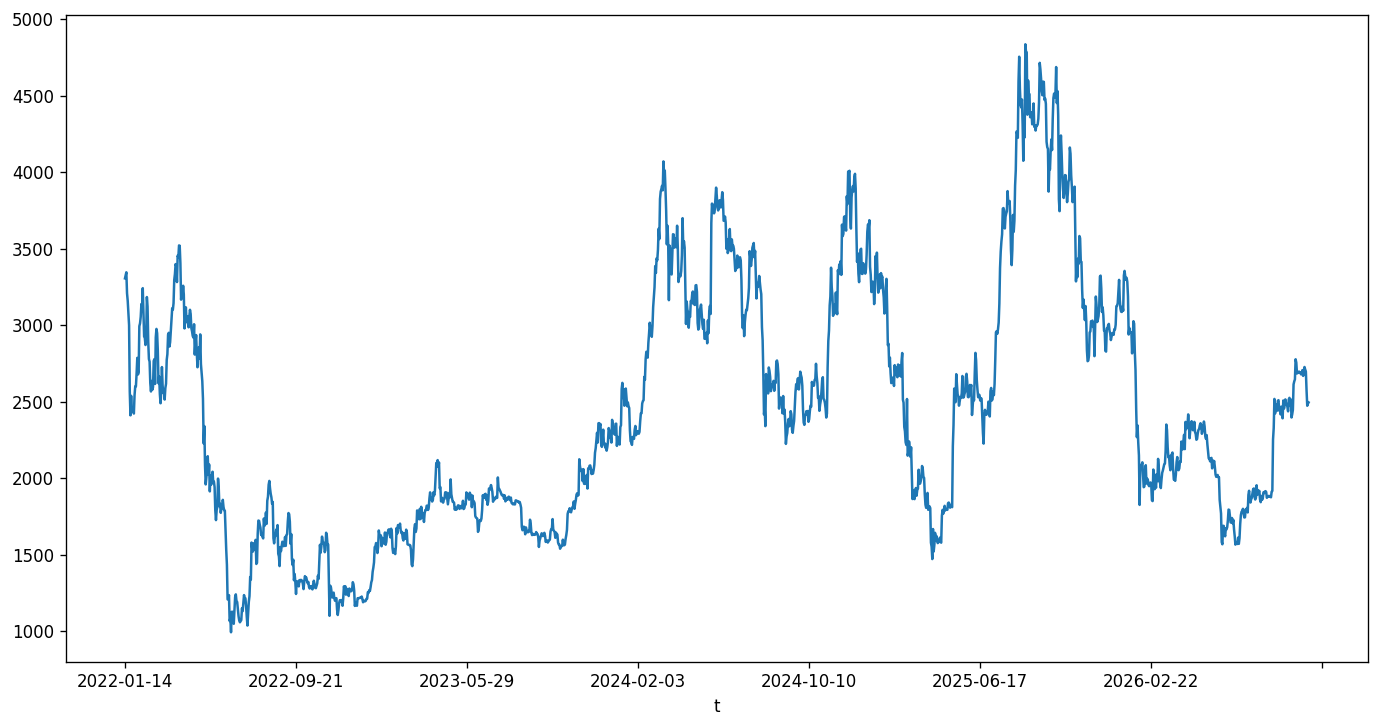

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 7), dpi=120)
df['ETH_c'].plot()

In [8]:
trade_size = 20.0

def plot_linear_model(target, features):
    model   = LinearRegression()
    model.fit(df_train[features], df_train[target])

    y_hat   = model.predict(df_train[features])
    df_train['y_hat']          = y_hat
    df_train['signal']         = np.sign(df_train['y_hat'])
    df_train['trade_return']   = df_train['signal'] * df_train[target]
    df_train['trade_gross_pnl']= df_train['trade_return'] * trade_size

    y_hat   = model.predict(df_test[features])
    df_test['y_hat']          = y_hat
    df_test['signal']         = np.sign(df_test['y_hat'])
    df_test['trade_return']   = df_test['signal'] * df_test[target]
    df_test['trade_gross_pnl']= df_test['trade_return'] * trade_size

    y_hat   = model.predict(df[features])
    trades  = df.copy()
    trades['y_hat']          = y_hat
    trades['signal']         = np.sign(trades['y_hat'])
    trades['trade_return']   = trades['signal'] * trades[target]
    trades['trade_gross_pnl']= trades['trade_return'] * trade_size


    stats = {
        'target':          target,
        'features':        features,
        'model':          'linear',
        'model_coef':      model.coef_,
        'model_intercept': model.intercept_,
        'test_mean':       df_test['trade_return'].mean(),
        'test_std':        df_test['trade_return'].std(),
        'test_wr':         (df_test['trade_return'] > 0).mean(),
        'test_mean':       df_train['trade_return'].mean(),
        'train_std':       df_train['trade_return'].std(),
        'train_wr':        (df_train['trade_return'] > 0).mean(),
        'total_gross_pnl': trades['trade_gross_pnl'].sum(),
    }

    trades['trade_gross_pnl'].cumsum().plot(title=f'Gross Pnl for {target} using {features}', figsize=(12, 6))

    return stats

{'target': 'ETH_return',
 'features': ['ETH_return_lag_1'],
 'model': 'linear',
 'model_coef': array([0.0141148]),
 'model_intercept': 0.005457855331127519,
 'test_mean': 0.005418470419750158,
 'test_std': 0.0859682436309614,
 'test_wr': 0.48498845265588914,
 'train_std': 0.09848610226659117,
 'train_wr': 0.5038520801232665,
 'total_gross_pnl': 125.48519626118616}

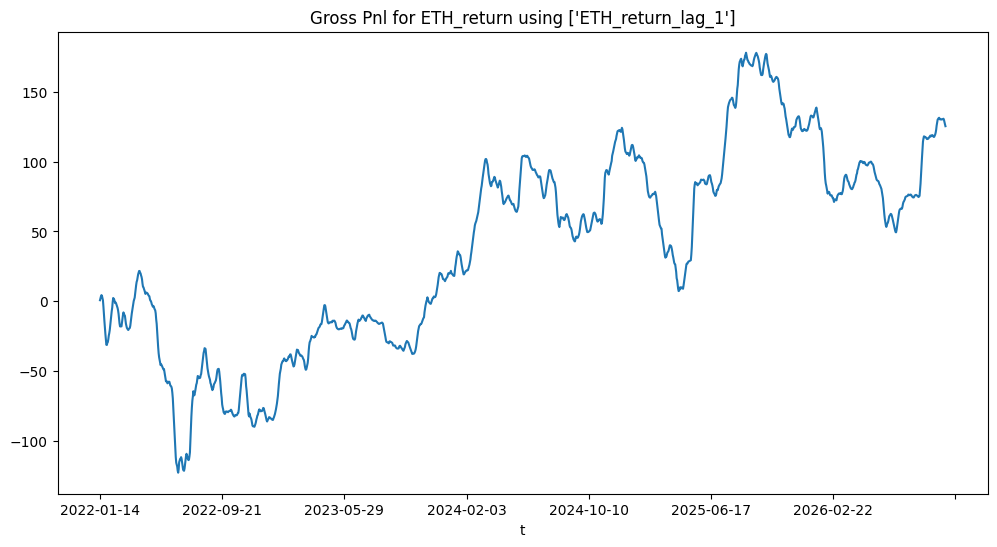

In [9]:
######## AR model #########
plot_linear_model('ETH_return', ['ETH_return_lag_1'])

{'target': 'ETH_return',
 'features': ['BNB_return_lag_1'],
 'model': 'linear',
 'model_coef': array([-0.06174653]),
 'model_intercept': 0.00586478621297142,
 'test_mean': 0.00737167418046365,
 'test_std': 0.08573444609817232,
 'test_wr': 0.5381062355658198,
 'train_std': 0.09835909373284213,
 'train_wr': 0.5200308166409862,
 'total_gross_pnl': 248.2371595238771}

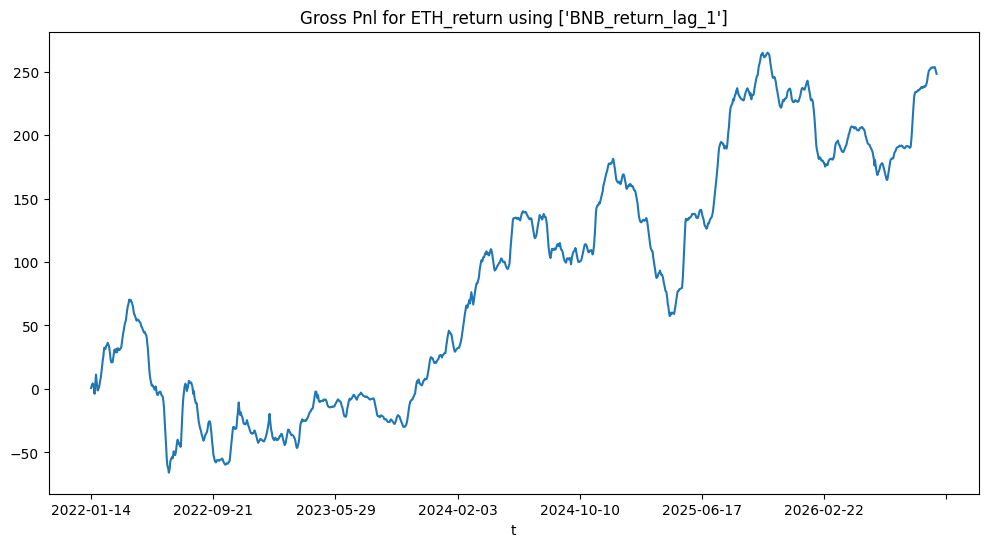

In [10]:
######### Distributed Lag model ##############
plot_linear_model('ETH_return', ['BNB_return_lag_1'])


{'target': 'ETH_return',
 'features': ['ETH_return_lag_1', 'BNB_return_lag_1'],
 'model': 'linear',
 'model_coef': array([ 0.09741486, -0.14955103]),
 'model_intercept': 0.005859134892976965,
 'test_mean': 0.00814988745826585,
 'test_std': 0.08568717190905419,
 'test_wr': 0.5196304849884527,
 'train_std': 0.0982976241904689,
 'train_wr': 0.5130970724191063,
 'total_gross_pnl': 273.54182274800314}

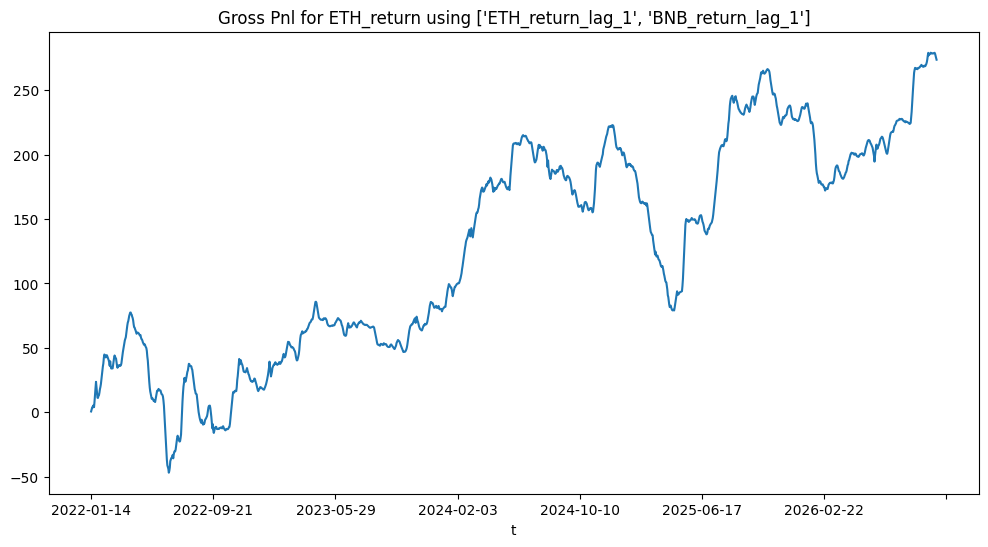

In [11]:
############# Auto-Regressive Distributed Lag Model ####################
plot_linear_model('ETH_return', ['ETH_return_lag_1', 'BNB_return_lag_1'])

{'target': 'ETH_return',
 'features': ['BNB_return_lag_1', 'SNX_return_lag_1'],
 'model': 'linear',
 'model_coef': array([-0.13401809,  0.06471441]),
 'model_intercept': 0.006326718368289256,
 'test_mean': 0.0087793329038376,
 'test_std': 0.08524118932975483,
 'test_wr': 0.5496535796766744,
 'train_std': 0.09824336458477956,
 'train_wr': 0.5254237288135594,
 'total_gross_pnl': 325.60572393439656}

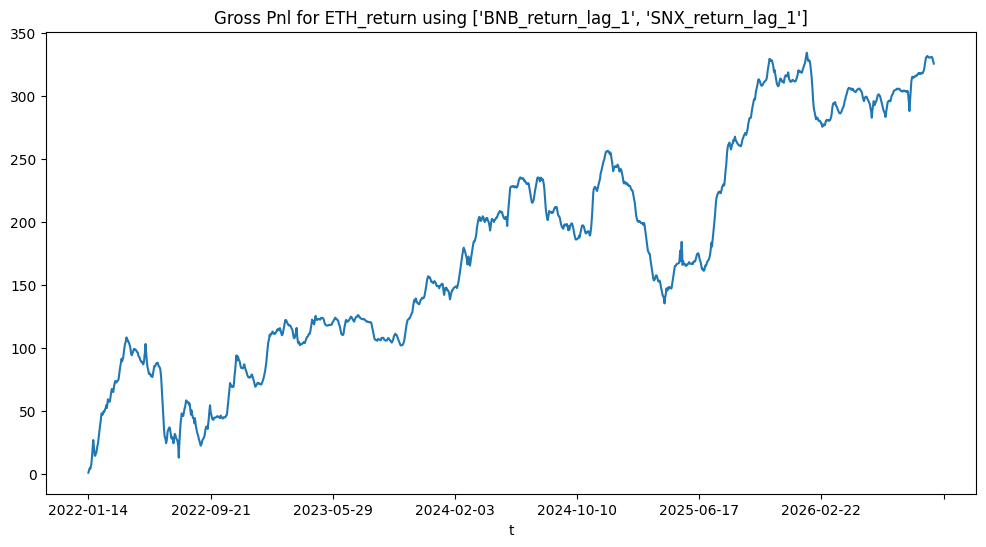

In [12]:
########## Cross-Asset Distributed Lag model ###############
plot_linear_model('ETH_return', ['BNB_return_lag_1', 'SNX_return_lag_1'])

{'target': 'ETH_return',
 'features': ['BNB_return_lag_1', 'CRV_return_lag_1', 'UNI_return_lag_1'],
 'model': 'linear',
 'model_coef': array([-0.23437714,  0.09295164,  0.0501833 ]),
 'model_intercept': 0.006229123320415894,
 'test_mean': 0.0123776580391576,
 'test_std': 0.08501762911152863,
 'test_wr': 0.5565819861431871,
 'train_std': 0.09785484278181301,
 'train_wr': 0.5469953775038521,
 'total_gross_pnl': 432.6439796115985}

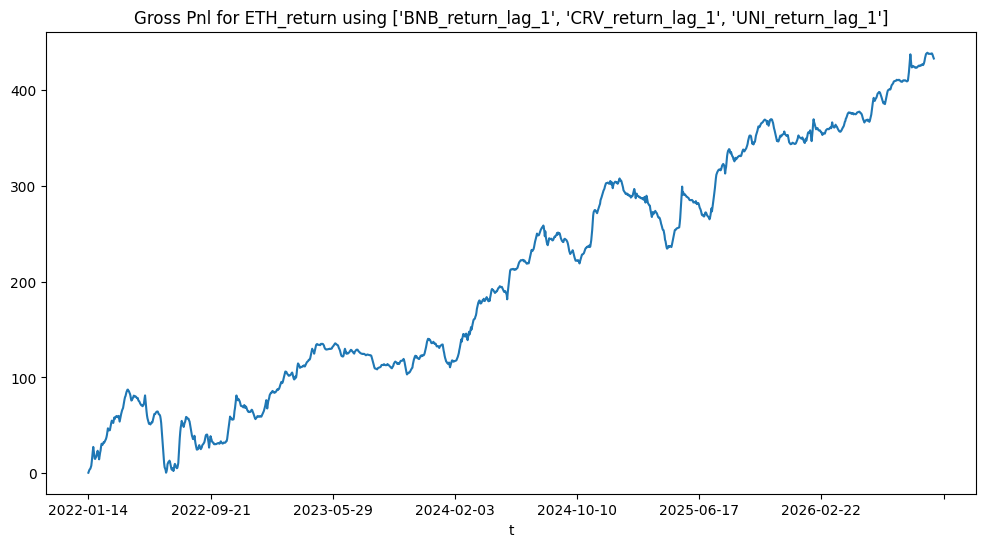

In [13]:
####### Cross Asset Relative Strength ###############
plot_linear_model('ETH_return', ['BNB_return_lag_1', 'CRV_return_lag_1', 'UNI_return_lag_1'])

In [ ]:
#########
